# Crop / weed segmentation on green beans — Phase I; midpoint submission

**Team:** *AI Gangsta*

**Model under analysis:** DeepLabV3+ with a MobileNetV2 encoder, RGB input at 1280 px, 4.4 M parameters, trained to segment top-down field images into **soil / crop (beans) / weeds**.

This notebook is the first deliverable of Phase I; studying how does the model behave.

**Contents**

1. Task and dataset
2. Model and training
3. Evaluation protocol and scores
4. Behaviour analysis — first pass
5. Reproducibility
6. Open questions and plan

In [19]:
import json, sys, platform
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib as mpl, matplotlib.pyplot as plt

# locate the handover root (folder that holds splits/, data/, predictions/, scripts/)
ROOT = Path.cwd().resolve()
while not (ROOT / "splits").is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
assert (ROOT / "splits").is_dir(), "run this notebook from inside the handover folder"
sys.path.insert(0, str(ROOT / "scripts"))
import beans_common as bc
PRED = ROOT / "predictions"
FIG = Path.cwd() / "figures"; FIG.mkdir(exist_ok=True)

# plotting defaults: one colour per entity, fixed everywhere in this notebook
C = {"soil": "#2a78d6", "crop": "#eb6834", "weed": "#1baf7a",          # classes
     "rose2_haricot": "#2a78d6", "rose3_haricot": "#eb6834",            # varieties
     "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e4e3df", "surface": "#fcfcfb"}
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
mpl.rcParams.update({"figure.dpi": 110, "figure.facecolor": C["surface"], "axes.facecolor": C["surface"],
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": C["ink2"],
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "text.color": C["ink"], "axes.labelcolor": C["ink2"], "xtick.color": C["ink2"], "ytick.color": C["ink2"],
    "legend.frameon": False})
pd.set_option("display.max_colwidth", None); pd.set_option("display.width", 160)
def savefig(name): plt.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show()
print("handover root:", ROOT)

handover root: C:\workspace_farming\practical work\DeepLab_beans\handover


## 1. Task and dataset

**Task.** Pixel-wise semantic segmentation of top-down images of a green-bean field into three classes: soil (0), crop (1), weed (2). The downstream use is spot spraying: the sprayer must hit weed pixels and must not hit crop pixels. Crop/weed confusions and errors at plant boundaries are therefore the behaviours that matter, not overall pixel accuracy.

**Source material.** 300 annotated samples of two bean varieties (`rose2_haricot`, `rose3_haricot`), imaged with a six-band Airphen multispectral camera at 800 × 1200 px. Leaf-level polygon annotations (`Crop leaf`, `Weed leaf`) were rasterised to colour masks. The raw data ships in `data/raw/`; the published dataset and paper are referenced in the main `README.md`.

**Model input.** The model sees an RGB rendering built from the 675 / 570 / 450 nm bands with a per-image 1–99 percentile stretch (`data/rgb/images`). Because the stretch is per image, absolute brightness is removed before the model ever sees the data.

**Splits.** Fixed, seed 48, stratified on crop presence: 210 train / 30 val / 60 test. Val drove early stopping and checkpoint selection, so only **test** is untouched.

In [20]:
man = pd.read_csv(ROOT / "data" / "dataset_manifest.csv")
counts = man["class_pixel_counts"].apply(json.loads)
for k, n in zip(["0", "1", "2"], ["soil", "crop", "weed"]):
    man[f"px_{n}"] = counts.apply(lambda d: d[k])
man["px_total"] = man[["px_soil", "px_crop", "px_weed"]].sum(axis=1)
for n in ["soil", "crop", "weed"]:
    man[f"frac_{n}"] = man[f"px_{n}"] / man["px_total"]
man["variety"] = man["sample_id"].map(bc.variety_of)
split_of = {i: s for s in ["train", "val", "test"] for i in bc.read_split(ROOT, s)}
man["split"] = man["sample_id"].map(split_of)
man["has_crop"] = man["px_crop"] > 0

print("images per variety and split")
display(pd.crosstab(man["variety"], man["split"], margins=True).loc[:, ["train", "val", "test", "All"]])
share = man.groupby("split")[["px_soil", "px_crop", "px_weed"]].sum()
share = (share.div(share.sum(axis=1), axis=0) * 100).round(1).loc[["train", "val", "test"]]
share.columns = ["soil %", "crop %", "weed %"]
share["crop-free images"] = man.groupby("split")["has_crop"].apply(lambda s: int((~s).sum()))
print("pixel share per split and crop-free images")
display(share)

images per variety and split


split,train,val,test,All
variety,,,,
rose2_haricot,127,16,33,176
rose3_haricot,83,14,27,124
All,210,30,60,300


pixel share per split and crop-free images


,soil %,crop %,weed %,crop-free images
split,,,,
train,80.6,8.3,11.1,19
val,76.7,7.5,15.8,3
test,78.4,8.8,12.7,5


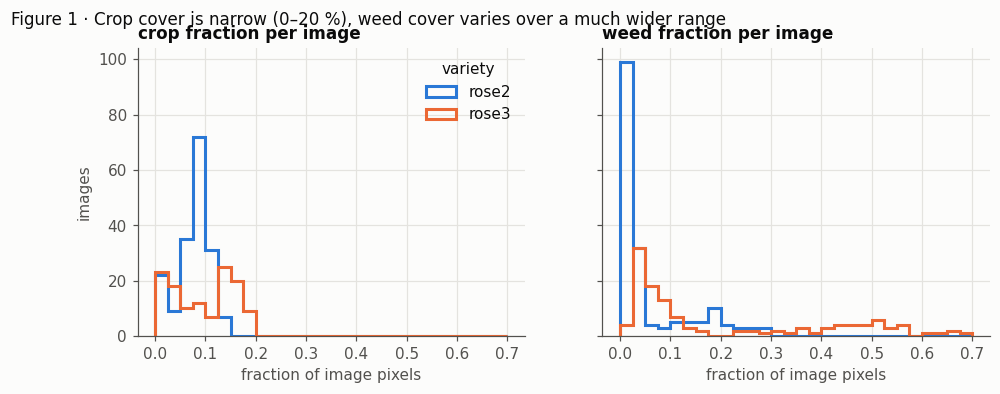

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
bins = np.linspace(0, 0.7, 29)
for ax, cls in zip(axes, ["crop", "weed"]):
    for v in ["rose2_haricot", "rose3_haricot"]:
        ax.hist(man.loc[man.variety == v, f"frac_{cls}"], bins=bins, histtype="step", linewidth=2,
                color=C[v], label=v.split("_")[0])
    ax.set_title(f"{cls} fraction per image"); ax.set_xlabel("fraction of image pixels")
axes[0].set_ylabel("images"); axes[0].legend(title="variety", loc="upper right")
fig.suptitle("Figure 1 · Crop cover is narrow (0–20 %), weed cover varies over a much wider range", x=0.01, ha="left", fontsize=11)
savefig("fig1_class_fraction_hist")

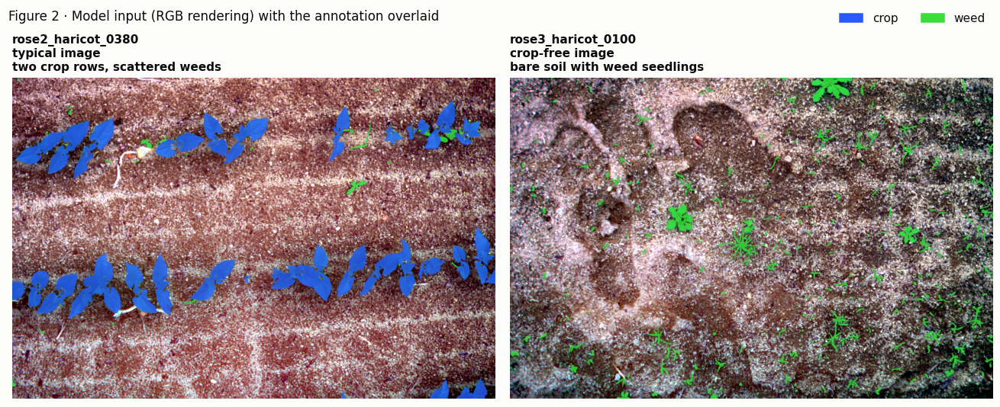

In [22]:
examples = [("rose2_haricot_0380", "typical image\ntwo crop rows, scattered weeds"),
            ("rose3_haricot_0100", "crop-free image\nbare soil with weed seedlings")]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (sid, what) in zip(axes, examples):
    img = bc.load_image_rgb(bc.image_path(ROOT, sid)); gt = bc.load_mask(bc.mask_path(ROOT, sid))
    ax.imshow(bc.overlay(img, gt, alpha=0.8)); ax.axis("off"); ax.set_title(f"{sid}\n{what}", fontsize=10)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=np.array(bc.PALETTE_RGB[1]) / 255, label="crop"), Patch(color=np.array(bc.PALETTE_RGB[2]) / 255, label="weed")],
           loc="upper right", ncol=2, bbox_to_anchor=(0.99, 1.06))
fig.suptitle("Figure 2 · Model input (RGB rendering) with the annotation overlaid", x=0.01, y=1.04, ha="left", fontsize=11)
plt.tight_layout(); savefig("fig2_examples")

**What this means for the analysis.** Soil is about 81 % of all pixels, so pixel accuracy says little. Crop appears as a few large objects (fraction 0–20 % per image), while weed cover ranges from almost nothing to two thirds of an image, so "weed" is really two regimes: dense patches and isolated seedlings. 27 images contain no crop at all (19 / 3 / 5 across train / val / test); on them, every predicted crop pixel is a false positive, which makes them a ready-made probe group.

## 2. Model and training

**Architecture.** `segmentation_models_pytorch` DeepLabV3+ with a MobileNetV2 encoder (ImageNet-pretrained at the start of training), output stride 16, ASPP (rates 12 / 24 / 36 + image pooling), a decoder that fuses the ASPP output with the stride-4 encoder feature, a 1 × 1 classifier at stride 4 and bilinear 4× upsampling. `model/layers.csv` lists every module with its output shape.

**Training recipe** (full configuration in `run_metadata/config.json`):

| | |
|---|---|
| Loss | class-weighted cross-entropy (soil 0.137, crop 1.333, weed 1.0; median-frequency balancing on train) + 0.5 × soft Dice |
| Optimiser | AdamW, lr 3e-4, weight decay 1e-4, gradient clipping at norm 1.0 |
| Schedule | 3 warm-up epochs, cosine decay to 1e-6 over a 400-epoch horizon |
| Batch / precision | 2 images, mixed precision, 1280 × 1280 input (longest side 1280, centre-padded, padding ignored) |
| Augmentation | flips, 90° rotations, brightness/contrast ± 0.2, HSV jitter, Gaussian blur |
| Early stopping | patience 30 on val mIoU; stopped at epoch 119, best epoch 89 |

parameters per block (total 4,379,027)


,type,params,output_shape
module,,,
encoder,MobileNetV2Encoder,"2,223,872","(1, 3, 1280, 1280) | (1, 16, 640, 640) | (1, 24, 320, 320) | (1, 32, 160, 160) | (1, 96, 80, 80) | (1, 1280, 80, 80)"
decoder,DeepLabV3PlusDecoder,"2,154,384","(1, 256, 320, 320)"
segmentation_head,SegmentationHead,771,"(1, 3, 1280, 1280)"


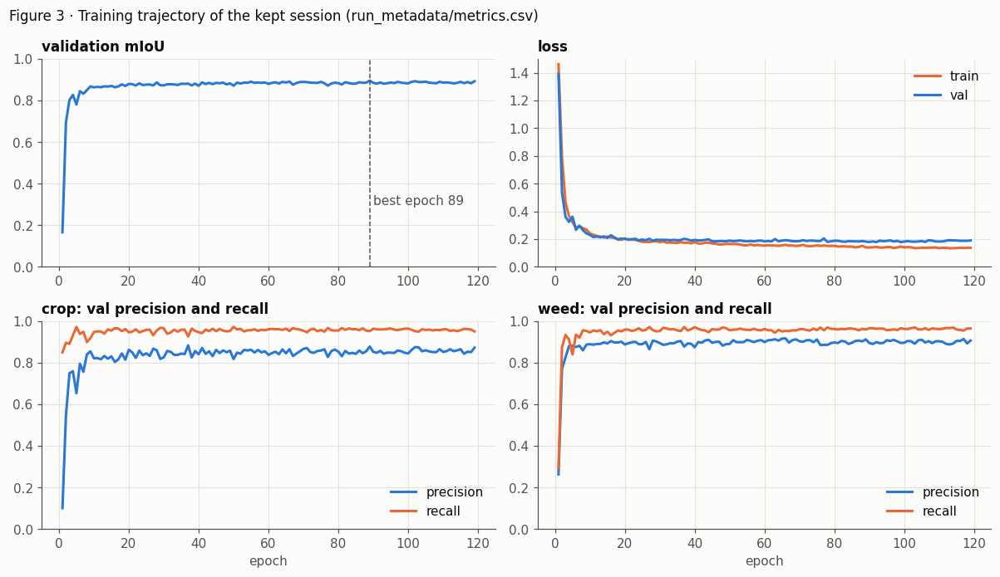

crop precision at epoch 5: 0.65, at epoch 89: 0.88; crop recall at epoch 5: 0.97
val loss: min 0.179 at epoch 92, last 0.190


In [23]:
layers = pd.read_csv(ROOT / "model" / "layers.csv")
top = layers[~layers["module"].str.contains(r"\.")].copy()
top["params"] = top["params"].map("{:,}".format)
print("parameters per block (total 4,379,027)")
display(top[["module", "type", "params", "output_shape"]].set_index("module"))

hist = pd.read_csv(ROOT / "run_metadata" / "metrics.csv")
best = int(hist.loc[hist["val_mIoU"].idxmax(), "epoch"])
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
ax = axes[0, 0]; ax.plot(hist.epoch, hist.val_mIoU, color=C["soil"], lw=2)
ax.axvline(best, color=C["ink2"], lw=1, ls="--"); ax.text(best + 1, 0.3, f"best epoch {best}", color=C["ink2"])
ax.set_title("validation mIoU"); ax.set_ylim(0, 1)
ax = axes[0, 1]; ax.plot(hist.epoch, hist.train_loss, color=C["crop"], lw=2, label="train")
ax.plot(hist.epoch, hist.val_loss, color=C["soil"], lw=2, label="val"); ax.set_title("loss"); ax.legend(); ax.set_ylim(0, 1.5)
for ax, cls in zip(axes[1], ["crop", "weed"]):
    ax.plot(hist.epoch, hist[f"val_prec_{cls}"], color=C["soil"], lw=2, label="precision")
    ax.plot(hist.epoch, hist[f"val_rec_{cls}"], color=C["crop"], lw=2, label="recall")
    ax.set_title(f"{cls}: val precision and recall"); ax.set_ylim(0, 1); ax.set_xlabel("epoch"); ax.legend(loc="lower right")
fig.suptitle("Figure 3 · Training trajectory of the kept session (run_metadata/metrics.csv)", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); savefig("fig3_training_curves")
e = hist.set_index("epoch")
print(f"crop precision at epoch 5: {e.loc[5,'val_prec_crop']:.2f}, at epoch {best}: {e.loc[best,'val_prec_crop']:.2f}; "
      f"crop recall at epoch 5: {e.loc[5,'val_rec_crop']:.2f}")
print(f"val loss: min {hist.val_loss.min():.3f} at epoch {int(hist.loc[hist.val_loss.idxmin(),'epoch'])}, last {hist.val_loss.iloc[-1]:.3f}")

**Reading the curves.** Recall for both vegetation classes is high within a handful of epochs, while precision keeps improving for most of the run: the network learns *where vegetation is* quickly and *which vegetation is crop* slowly. Crop precision climbs from 0.65 at epoch 5 to 0.88 at the best epoch while crop recall is 0.97 from epoch 5 on. Val mIoU plateaus around epoch 60 and the remaining epochs move it by thousandths; the same configuration trained twice more with the same seed landed within 0.001 mIoU, so differences smaller than that are noise. Val loss bottoms out around epoch 90 and creeps up afterwards while train loss keeps falling, which is why the calibration of the selected weights is examined in section 4.

## 3. Evaluation protocol and scores

All metrics come from one pixel confusion matrix accumulated over a split; padding pixels are excluded. mIoU is the plain mean over the three classes. Two scorings are reported: **network resolution** (the 1280 grid with a nearest-resized ground truth, exactly how training evaluated the model) and **original resolution** (logits interpolated back to 800 × 1200, then argmax). The scripts in `scripts/` produce both; the network-resolution test numbers reproduce the archived `run_metadata/eval_final.json` to within 2e-5.

In [24]:
runs = [("best (ep 89)", "train", PRED / "train"), ("best (ep 89)", "val", PRED / "val"),
        ("best (ep 89)", "test", PRED / "test"), ("last (ep 119)", "test", PRED / "last_epoch119" / "test")]
rows = []
for ck, split, d in runs:
    m = json.load(open(d / "metrics.json"))
    for scoring in ["network_resolution", "original_resolution"]:
        s = m[scoring]
        rows.append({"checkpoint": ck, "split": f"{split} ({m['n_images']})", "scoring": scoring.split("_")[0],
                     "mIoU": s["mIoU"], "IoU soil": s["IoU_soil"], "IoU crop": s["IoU_crop"], "IoU weed": s["IoU_weed"],
                     "pixel acc": s["pixel_acc"], "prec crop": s["prec_crop"], "rec crop": s["rec_crop"],
                     "prec weed": s["prec_weed"], "rec weed": s["rec_weed"]})
scores = pd.DataFrame(rows).set_index(["checkpoint", "split", "scoring"]).round(4)
display(scores)
mt = json.load(open(PRED / "test" / "metrics.json"))

mIoU  IoU soil  IoU crop  IoU weed  pixel acc  prec crop  rec crop  prec weed  rec weed
checkpoint    split       scoring                                                                                            
best (ep 89)  train (210) network   0.9021    0.9700    0.8809    0.8552     0.9734     0.9028    0.9733     0.8894    0.9570
                          original  0.8994    0.9691    0.8761    0.8530     0.9727     0.9000    0.9706     0.8883    0.9554
              val (30)    network   0.8953    0.9678    0.8403    0.8779     0.9702     0.8775    0.9519     0.9120    0.9592
                          original  0.8933    0.9669    0.8364    0.8765     0.9696     0.8750    0.9498     0.9113    0.9583
              test (60)   network   0.8859    0.9645    0.8559    0.8373     0.9672     0.8892    0.9580     0.8820    0.9429
                          original  0.8833    0.9634    0.8520    0.8343     0.9663     0.8871    0.9557     0.8807    0.9406
last (ep 119) test (60)   network   0.8853    0.9639    0.8540    0.8381     0.9668     0.8854    0.9601     0.8787    0.9478
                          original  0.8829    0.9629    0.8510    0.8348     0.9660     0.8837    0.9582     0.8771    0.9454

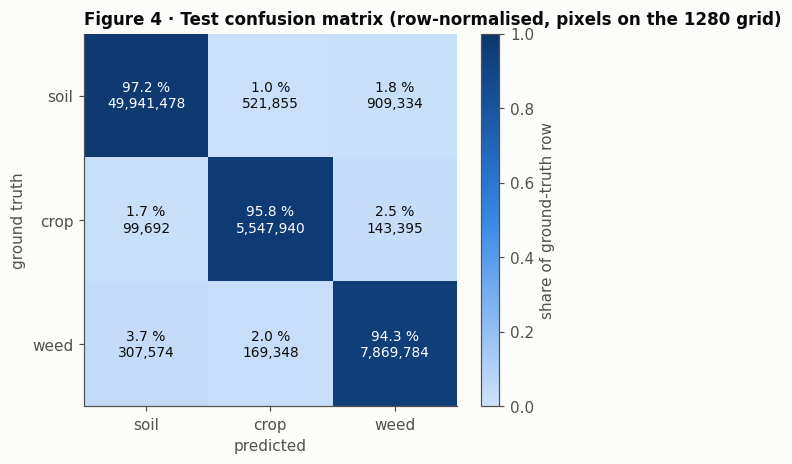

share of all wrong test pixels by error type:
  soil → weed   42.3 %
  soil → crop   24.3 %
  weed → soil   14.3 %
  weed → crop    7.9 %
  crop → weed    6.7 %
  crop → soil    4.6 %


In [25]:
cm = np.array(mt["confusion_matrix_network_resolution"], dtype=float)
rown = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.6, 4.4))
im = ax.imshow(rown, cmap=mpl.colors.LinearSegmentedColormap.from_list("seq", SEQ), vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{rown[i, j]*100:.1f} %\n{int(cm[i, j]):,}", ha="center", va="center",
                color="white" if rown[i, j] > 0.5 else C["ink"], fontsize=9)
ax.set_xticks(range(3)); ax.set_yticks(range(3)); ax.set_xticklabels(bc.CLASS_NAMES); ax.set_yticklabels(bc.CLASS_NAMES)
ax.set_xlabel("predicted"); ax.set_ylabel("ground truth"); ax.grid(False)
ax.set_title("Figure 4 · Test confusion matrix (row-normalised, pixels on the 1280 grid)")
plt.colorbar(im, ax=ax, fraction=0.046, label="share of ground-truth row")
savefig("fig4_confusion_test")
err = {"soil → crop": cm[0, 1], "soil → weed": cm[0, 2], "crop → soil": cm[1, 0], "weed → soil": cm[2, 0],
       "crop → weed": cm[1, 2], "weed → crop": cm[2, 1]}
tot = sum(err.values())
print("share of all wrong test pixels by error type:")
for k, v in sorted(err.items(), key=lambda kv: -kv[1]): print(f"  {k:12s} {v/tot*100:5.1f} %")

**Reading the scores.** Test mIoU is 0.886 with soil 0.964, crop 0.856, weed 0.837. The train/test gap is only 0.016 and the last-epoch weights are within 0.001 of the selected checkpoint, so neither over-fitting nor checkpoint choice is a big factor. Both vegetation classes have recall above precision, and two thirds of all wrong pixels are **soil predicted as vegetation**: the model over-segments plants. Crop/weed swaps are a small share of pixels, but they are the errors that matter for spraying, so section 4 looks at where they occur.

## 4. Behaviour analysis — first pass

The questions below are answered from the pre-computed predictions (`predictions/<split>/per_image.csv`, class masks and softmax probabilities). Each one is a starting point that the remaining Phase I work will deepen.

### 4.1 Is the aggregate score representative of single images?

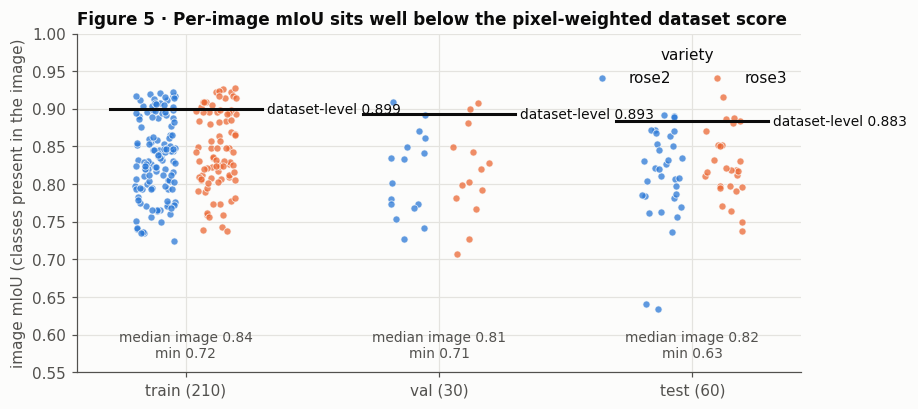

In [26]:
per = pd.concat([pd.read_csv(PRED / s / "per_image.csv") for s in ["train", "val", "test"]], ignore_index=True)
per["split"] = pd.Categorical(per["split"], ["train", "val", "test"])
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(8.5, 4))
for k, split in enumerate(["train", "val", "test"]):
    sub = per[per.split == split]
    for v in ["rose2_haricot", "rose3_haricot"]:
        ss = sub[sub.variety == v]
        off = -0.12 if v.startswith("rose2") else 0.12
        ax.scatter(k + off + rng.uniform(-0.08, 0.08, len(ss)), ss.mIoU_present_classes, s=22, color=C[v], alpha=0.75,
                   edgecolor=C["surface"], linewidth=0.6, label=v.split("_")[0] if k == 0 else None)
    agg = json.load(open(PRED / split / "metrics.json"))["original_resolution"]["mIoU"]
    ax.plot([k - 0.3, k + 0.3], [agg, agg], color=C["ink"], lw=2)
    ax.text(k + 0.32, agg, f"dataset-level {agg:.3f}", va="center", fontsize=9, color=C["ink"])
    med = sub.mIoU_present_classes.median()
    ax.text(k, 0.57, f"median image {med:.2f}\nmin {sub.mIoU_present_classes.min():.2f}", ha="center", fontsize=9, color=C["ink2"])
ax.set_xticks(range(3)); ax.set_xticklabels(["train (210)", "val (30)", "test (60)"]); ax.set_ylim(0.55, 1.0)
ax.set_ylabel("image mIoU (classes present in the image)"); ax.legend(title="variety", loc="upper right", ncol=2)
ax.set_title("Figure 5 · Per-image mIoU sits well below the pixel-weighted dataset score")
savefig("fig5_per_image_miou")

The dataset-level mIoU is pixel-weighted, so images with large plants dominate it. Per image, the median is around 0.82 and the worst test images fall to 0.63. The spread is similar in all three splits, which again argues against over-fitting and for a per-image or per-object analysis rather than a single score.

### 4.2 Which images fail, and why?

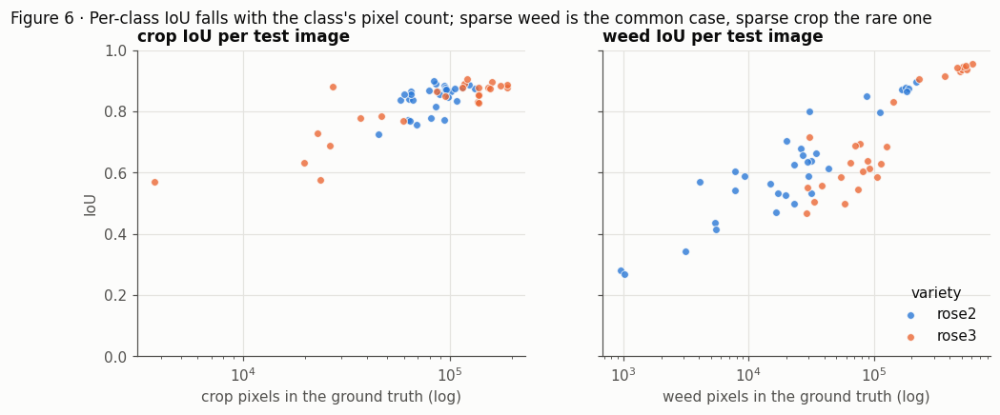

six worst test images


,mIoU_present_classes,IoU_crop,IoU_weed,gt_pixels_crop,gt_pixels_weed,crop_pred_as_weed,weed_pred_as_crop,soil_pred_as_plant
id,,,,,,,,
rose2_haricot_0324,0.634,NaN,0.270,0,1026,0,0,525
rose2_haricot_0322,0.640,NaN,0.281,0,942,0,0,362
rose2_haricot_0380,0.736,0.878,0.343,94834,3137,1462,574,9156
rose3_haricot_0100,0.738,NaN,0.504,0,33022,0,0,20307
rose3_haricot_0094,0.750,0.830,0.467,136935,28749,2084,4613,33497
rose2_haricot_0196,0.756,0.815,0.471,85988,16408,812,5543,13128


correlation of crop IoU with log crop pixel count (test, 55 images): r = 0.81
correlation of weed IoU with log weed pixel count (test, 60 images): r = 0.88


In [27]:
test = per[per.split == "test"].copy()
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, cls in zip(axes, ["crop", "weed"]):
    sub = test[test[f"gt_pixels_{cls}"] > 0]
    for v in ["rose2_haricot", "rose3_haricot"]:
        ss = sub[sub.variety == v]
        ax.scatter(ss[f"gt_pixels_{cls}"], ss[f"IoU_{cls}"], s=26, color=C[v], alpha=0.8, edgecolor=C["surface"], linewidth=0.6,
                   label=v.split("_")[0])
    ax.set_xscale("log"); ax.set_xlabel(f"{cls} pixels in the ground truth (log)"); ax.set_title(f"{cls} IoU per test image")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("IoU"); axes[1].legend(title="variety", loc="lower right")
fig.suptitle("Figure 6 · Per-class IoU falls with the class's pixel count; sparse weed is the common case, sparse crop the rare one", x=0.01, ha="left", fontsize=11)
savefig("fig6_iou_vs_pixels")
worst = test.nsmallest(6, "mIoU_present_classes")[["id", "mIoU_present_classes", "IoU_crop", "IoU_weed", "gt_pixels_crop", "gt_pixels_weed",
                                                   "crop_pred_as_weed", "weed_pred_as_crop", "soil_pred_as_plant"]]
print("six worst test images"); display(worst.round(3).set_index("id"))
for cls in ["crop", "weed"]:
    sub = test[test[f"gt_pixels_{cls}"] > 0]
    r = np.corrcoef(np.log10(sub[f"gt_pixels_{cls}"]), sub[f"IoU_{cls}"])[0, 1]
    print(f"correlation of {cls} IoU with log {cls} pixel count (test, {len(sub)} images): r = {r:.2f}")

In [28]:
groups = {}
for name in ["by_variety", "by_has_crop"]:
    g = json.load(open(PRED / "test" / "eval" / f"eval_{name}.json"))["groups"]
    for k, v in g.items():
        m = v["metrics"]; cmg = np.array(v["confusion_matrix"])
        groups[k] = {"images": None, "mIoU": m["mIoU"], "IoU soil": m["IoU_soil"], "IoU crop": m["IoU_crop"], "IoU weed": m["IoU_weed"],
                     "prec weed": m["prec_weed"], "rec weed": m["rec_weed"], "crop px predicted": int(cmg[:, 1].sum())}
groups["rose2_haricot"]["images"] = int((test.variety == "rose2_haricot").sum()); groups["rose3_haricot"]["images"] = int((test.variety == "rose3_haricot").sum())
groups["has_crop"]["images"] = int(test.has_crop.sum()); groups["no_crop"]["images"] = int((~test.has_crop).sum())
print("test metrics by group (original resolution; scripts/evaluate_predictions.py --group ...)")
display(pd.DataFrame(groups).T.astype({"images": int, "crop px predicted": int}).round(3))

test metrics by group (original resolution; scripts/evaluate_predictions.py --group ...)


,images,mIoU,IoU soil,IoU crop,IoU weed,prec weed,rec weed,crop px predicted
rose2_haricot,33,0.871,0.977,0.848,0.787,0.843,0.921,2775049
rose3_haricot,27,0.883,0.942,0.856,0.850,0.893,0.947,2712145
has_crop,55,0.883,0.960,0.852,0.837,0.883,0.942,5487194
no_crop,5,0.787,0.991,0.000,0.584,0.655,0.843,0


Three observations:

- **Sparse vegetation is the failure mode, and weed is where it happens.** Per-image IoU of both classes tracks the class's pixel count (r ≈ 0.9 on a log scale), but crop is sparse in only a handful of images while weed is sparse in many. The worst test images have between about one thousand and thirty thousand weed pixels (out of 960 000) and weed IoU of 0.27–0.50, while crop IoU in the same images stays above 0.8. Small isolated seedlings, not crop/weed confusion, drive the worst cases.
- **Crop-free images do not fool the model.** On the five crop-free test images it predicts zero crop pixels. The expected false-positive probe is a non-finding; what those images show instead is the sparse-weed problem (weed IoU 0.58 as a group).
- **Variety matters for weed.** Weed IoU is 0.79 on rose2 against 0.85 on rose3, with soil going the other way. The varieties differ in weed density (Figure 1), so this may be a density effect in disguise; separating the two is an open task.

### 4.3 Where are the errors: boundaries or whole objects?

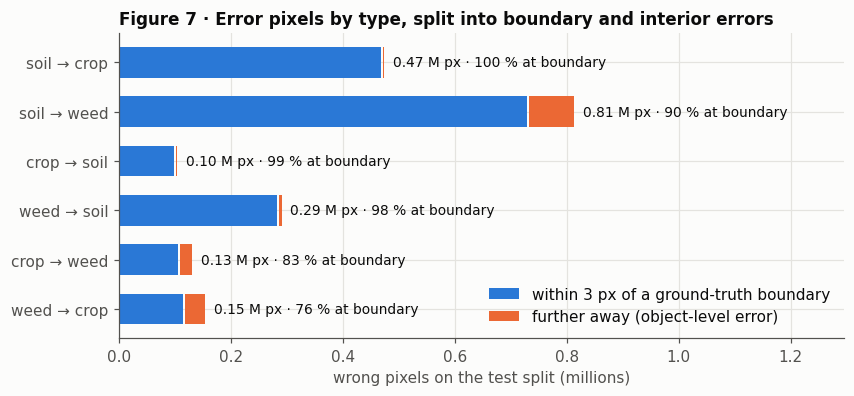

all errors: 1.94 M px, 93 % within 3 px of a boundary


In [29]:
# classify every wrong test pixel by type and by distance to the nearest ground-truth class boundary
kernel = np.ones((3, 3), np.uint8)
types = [("soil → crop", 0, 1), ("soil → weed", 0, 2), ("crop → soil", 1, 0), ("weed → soil", 2, 0), ("crop → weed", 1, 2), ("weed → crop", 2, 1)]
acc = {t[0]: {"near": 0, "far": 0} for t in types}
BAND = 3  # pixels
for sid in test.id:
    gt = bc.load_mask(bc.mask_path(ROOT, sid)); pr = bc.load_mask(PRED / "test" / "masks" / f"{sid}.png")
    edge = cv2.morphologyEx(gt, cv2.MORPH_GRADIENT, kernel) > 0
    near = cv2.dilate(edge.astype(np.uint8), np.ones((2 * BAND + 1, 2 * BAND + 1), np.uint8)) > 0
    for name, g, p in types:
        e = (gt == g) & (pr == p)
        acc[name]["near"] += int((e & near).sum()); acc[name]["far"] += int((e & ~near).sum())
bd = pd.DataFrame(acc).T; bd["total"] = bd.near + bd.far; bd["near share"] = bd.near / bd.total
fig, ax = plt.subplots(figsize=(8.5, 3.6))
y = np.arange(len(bd))[::-1]
ax.barh(y, bd.near / 1e6, color=C["soil"], height=0.62, label=f"within {BAND} px of a ground-truth boundary")
ax.barh(y, bd.far / 1e6, left=bd.near / 1e6 + 0.004, color=C["crop"], height=0.62, label="further away (object-level error)")
for yi, (name, row) in zip(y, bd.iterrows()):
    ax.text(row.total / 1e6 + 0.02, yi, f"{row.total/1e6:.2f} M px · {row['near share']*100:.0f} % at boundary", va="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(bd.index); ax.set_xlabel("wrong pixels on the test split (millions)"); ax.set_xlim(0, bd.total.max() / 1e6 * 1.6)
ax.legend(loc="lower right"); ax.set_title("Figure 7 · Error pixels by type, split into boundary and interior errors")
savefig("fig7_error_types_boundary")
print(f"all errors: {bd.total.sum()/1e6:.2f} M px, {bd.near.sum()/bd.total.sum()*100:.0f} % within {BAND} px of a boundary")

The split tells the two error families apart. 93 % of all wrong test pixels lie within 3 px of a ground-truth boundary. Vegetation-versus-soil errors are almost entirely that thin band around every leaf (90–100 % at the boundary): over-segmentation of the outline, which is cheap for spraying. Crop ↔ weed swaps have an interior share two to several times larger (17–24 % away from any boundary): these are plant parts or whole small plants labelled as the other class, the expensive error. Phase I should count these as objects (connected components or the polygon annotations), not as pixels.

### 4.4 Does the model know when it is wrong?

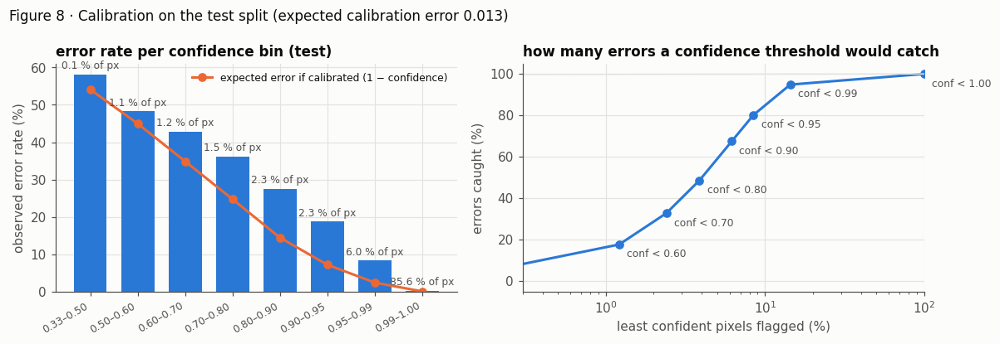

pixels with confidence < 0.9: 6.2 % of all pixels, containing 68 % of all errors
pixels with confidence >= 0.99: 85.6 % of all pixels, error rate 0.20 %


In [30]:
edges = np.array([1/3, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99, 1.0 + 1e-6])
n_pix = np.zeros(len(edges) - 1); n_err = np.zeros(len(edges) - 1); conf_sum = np.zeros(len(edges) - 1)
for sid in test.id:
    pr = np.load(PRED / "test" / "probs" / f"{sid}.npy").astype(np.float32)
    gt = bc.load_mask(bc.mask_path(ROOT, sid))
    conf = pr.max(axis=0); wrong = pr.argmax(axis=0) != gt
    b = np.clip(np.searchsorted(edges, conf, side="right") - 1, 0, len(edges) - 2)
    n_pix += np.bincount(b.ravel(), minlength=len(edges) - 1)
    n_err += np.bincount(b.ravel(), weights=wrong.ravel(), minlength=len(edges) - 1)
    conf_sum += np.bincount(b.ravel(), weights=conf.ravel(), minlength=len(edges) - 1)
err_rate = n_err / np.maximum(n_pix, 1); mean_conf = conf_sum / np.maximum(n_pix, 1); share = n_pix / n_pix.sum()
ece = float((share * np.abs((1 - err_rate) - mean_conf)).sum())
labels = [f"{a:.2f}–{b:.2f}" for a, b in zip(edges[:-1], edges[1:])]; labels[0] = "0.33–0.50"; labels[-1] = "0.99–1.00"
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]; x = np.arange(len(labels))
ax.bar(x, err_rate * 100, color=C["soil"], width=0.7)
ax.plot(x, (1 - mean_conf) * 100, color=C["crop"], lw=2, marker="o", ms=6, label="expected error if calibrated (1 − confidence)")
for xi, (e_, s_) in enumerate(zip(err_rate, share)):
    ax.text(xi, e_ * 100 + 1.5, f"{s_*100:.1f} % of px", ha="center", fontsize=8, color=C["ink2"])
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=8); ax.set_ylabel("observed error rate (%)")
ax.set_title("error rate per confidence bin (test)"); ax.legend(loc="upper right", fontsize=8)
ax = axes[1]
cum_err = np.cumsum(n_err) / n_err.sum(); cum_pix = np.cumsum(n_pix) / n_pix.sum()
ax.plot(cum_pix * 100, cum_err * 100, color=C["soil"], lw=2, marker="o", ms=6)
for xi, yi, lab in zip(cum_pix * 100, cum_err * 100, edges[1:]):
    ax.annotate(f"conf < {lab:.2f}", (xi, yi), textcoords="offset points", xytext=(6, -10), fontsize=8, color=C["ink2"])
ax.plot([0, 100], [0, 100], color=C["grid"], lw=1); ax.set_xlabel("least confident pixels flagged (%)"); ax.set_ylabel("errors caught (%)")
ax.set_title("how many errors a confidence threshold would catch"); ax.set_xscale("log"); ax.set_xlim(0.3, 100)
fig.suptitle(f"Figure 8 · Calibration on the test split (expected calibration error {ece:.3f})", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); savefig("fig8_calibration")
print(f"pixels with confidence < 0.9: {share[:-3].sum()*100:.1f} % of all pixels, containing {cum_err[-4]*100:.0f} % of all errors")
print(f"pixels with confidence >= 0.99: {share[-1]*100:.1f} % of all pixels, error rate {err_rate[-1]*100:.2f} %")

The model is well calibrated overall (expected calibration error 0.013): 86 % of pixels have confidence above 0.99 and their error rate is 0.2 %, and the middle bins are only slightly over-confident (observed error a few points above 1 − confidence). The errors concentrate in the low-confidence tail: the 6 % of pixels with confidence below 0.9 contain 68 % of all wrong pixels. A sprayer that treats uncertain pixels as "do not spray" would therefore remove most errors at a small cost in coverage. Whether the remaining *confident* errors are the crop/weed swaps is the next question.

### 4.5 Looking at the failure cases

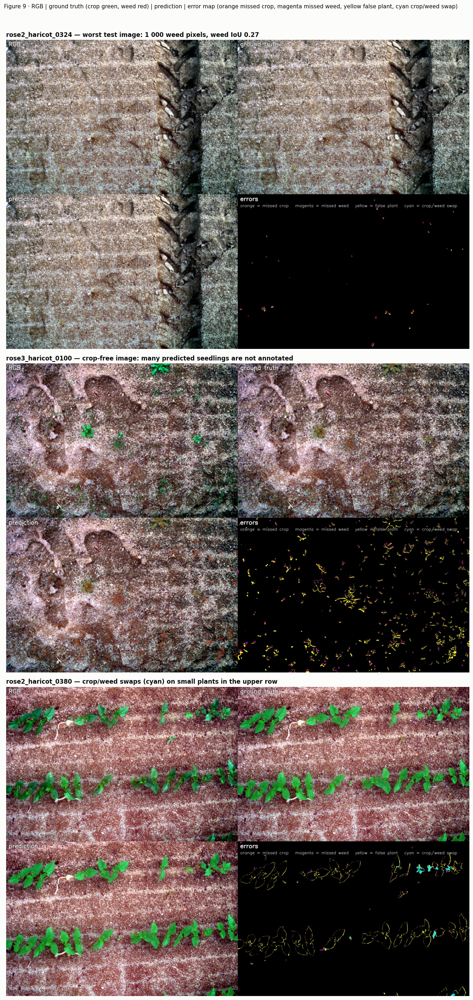

In [31]:
cases = [("rose2_haricot_0324", "worst test image: 1 000 weed pixels, weed IoU 0.27"),
         ("rose3_haricot_0100", "crop-free image: many predicted seedlings are not annotated"),
         ("rose2_haricot_0380", "crop/weed swaps (cyan) on small plants in the upper row")]
fig, axes = plt.subplots(len(cases), 1, figsize=(12, 8.4 * len(cases)))
for ax, (sid, what) in zip(axes, cases):
    ax.imshow(cv2.cvtColor(cv2.imread(str(PRED / "test" / "panels" / f"{sid}.jpg")), cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{sid} — {what}")
fig.suptitle("Figure 9 · RGB | ground truth (crop green, weed red) | prediction | error map (orange missed crop, magenta missed weed, yellow false plant, cyan crop/weed swap)",
             x=0.01, y=0.995, ha="left", fontsize=10)
plt.tight_layout(rect=(0, 0, 1, 0.985)); savefig("fig9_failure_panels")

The panels add a caveat to every weed number above: on sparse images many "false plant" pixels sit on real seedlings that the annotation does not mark. Part of the measured weed error is annotation incompleteness rather than model failure, and the two must be separated (for example with the polygon XML and the raw spectral bands) before weed IoU is used to rank anything.

## 5. Reproducibility

Everything in this notebook derives from files in the handover folder. The predictions were produced once with the shared scripts and can be regenerated:

```bash
pip install -r scripts/requirements.txt
python scripts/predict.py --split test val --save-probs --save-panels     # torch backend, GPU or CPU
python scripts/predict.py --split train
python scripts/predict.py --split test --checkpoint model/last.pt --out predictions/last_epoch119
python scripts/predict.py --split test --backend onnx                     # same result without PyTorch
python scripts/evaluate_predictions.py --pred predictions/test --group variety
python scripts/evaluate_predictions.py --pred predictions/test --group has_crop
```

The preprocessing in `scripts/beans_common.py` was checked against the training transform (max difference 2.4e-7 on the normalised tensor, identical masks), the ONNX export agrees with PyTorch on 99.9999 % of pixels, and `SHA256SUMS.txt` fixes every file in the package.

In [32]:
mt_full = json.load(open(PRED / "test" / "metrics.json"))
print("predictions produced with:", {k: mt_full[k] for k in ["checkpoint", "checkpoint_sha256", "epoch", "backend", "device", "torch"] if k in mt_full})
print("notebook executed with: python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| opencv", cv2.__version__, "| matplotlib", mpl.__version__)
print("figures written to", FIG)

predictions produced with: {'checkpoint': 'model/best.pt', 'checkpoint_sha256': '94c861a35c307a5370aae2b4f69bd8f9c772d7ede62cb951cce9d9bc4d1e1110', 'epoch': 89, 'backend': 'torch', 'device': 'cuda', 'torch': '2.7.1+cu118'}
notebook executed with: python 3.10.22 | numpy 1.26.0 | pandas 1.5.2 | opencv 4.11.0 | matplotlib 3.10.5
figures written to c:\workspace_farming\practical work\DeepLab_beans\handover\notebooks\figures


## 6. Open questions and plan

**Remaining Phase I (behaviour, black box)**

1. Object-level scoring, not only pixel wise: count crop/weed swaps and missed plants on instance wise, not pixel wise (connected components), and relate them to object size.
2. Separate annotation gaps from model errors on sparse weed images, using the polygon XML and the unused multi spectral bands (710 / 730 / 850 nm) as an independent vegetation signal.
3. Variety versus weed density: a matched comparison that holds weed cover constant.
5. Confident errors: are the crop/weed swaps high  or low confidence pixels?

**The rest of the question to be studied in the upcoming phase**